# 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.insert(1,"../src/")

In [30]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
import scipy.signal as sp
import scipy.optimize as op

import acoustic_inversion as ai

from utilities import scramble_nums

In [31]:
# [Title, Freq, ssp, bdry, pos, beam, cint, rmax] = at.read_env("feif_scenario.env", "KRAKEN")

In [32]:
normize = lambda p: p/p.sum()

In [33]:
SAMPLING_FREQ = 2000
TRUE_SOUNDSPEED = 1460
TRUE_DENSITY = 1.3

In [34]:
# np.savez("../data/output/warping_arrival_times_corrected.npz", **data_warped)

In [35]:
# Organizing the extracted peaks into a dictionary
data = {
    "STFT":{**ai.peaks_from_file("../data/output/full_arrival_times_fromkraken.npz"),
            'freq_range':(225, 400)},
    "Warping":{**ai.peaks_from_file("../data/output/warping_arrival_times_fromkraken1.npz"),
            'freq_range':(220, 475)}
}

In [36]:
# Loading replicas of the arrival times
replicas = scipy.io.loadmat("../data/field_values20260921/field_values20260921.mat")

f = replicas['f'].squeeze()
f_Vg = f[1:-1]
c = replicas['soundspeed'].squeeze()
Vg = replicas['Vg'].squeeze().transpose([2,1,0,3])
#Vg = Vg[data_components['mode_nos'].squeeze()]
receiver_range = replicas['range'][0,0]*1e3
rho = replicas['rho'].squeeze()
# nmodes, nspeed, nfreq = Vg.shape

In [37]:
at_replica = receiver_range/Vg
at_reference = receiver_range/Vg[rho==TRUE_DENSITY,c==TRUE_SOUNDSPEED].squeeze()

In [65]:
arrival_times = {}
for name in data:
    arrival_times[name] = {}
    for method in ['all', 'jagged']:
        arrival_times[name][method] = {}

        if method == 'all':
            fmask = (f_Vg >= data[name]['freq_range'][0]) &\
                    (f_Vg <= data[name]['freq_range'][1])
            regression_f = f_Vg[fmask]
            arrival_times[name][method]['replica'] = at_replica[...,fmask]
        if method == 'jagged':
            regression_f = f_Vg
            arrival_times[name][method]['replica'] = at_replica
    
        arrival_times[name][method]['data'],\
        arrival_times[name][method]['freqs'] =\
            ai.peaks_to_arrivaltimes(data[name]['peaks_coordinates'],
                                     deg = 2,
                                     freqs = regression_f,
                                     method = method,
                                     limit=np.inf)
    

In [66]:
likelihood = {}

for name in arrival_times:
    likelihood[name] = {}
    for method in arrival_times[name]:
        likelihood[name][method] = {}
        likelihood[name][method]['combined'] =\
            ai.likelihood_combined(arrival_times[name][method]['data'],
                                   arrival_times[name][method]['replica'][...,data[name]['mode_nos'],:])
        likelihood[name][method]['direct'] =\
            ai.likelihood_direct(arrival_times[name][method]['data'],
                                 arrival_times[name][method]['replica'][...,data[name]['mode_nos'],:])

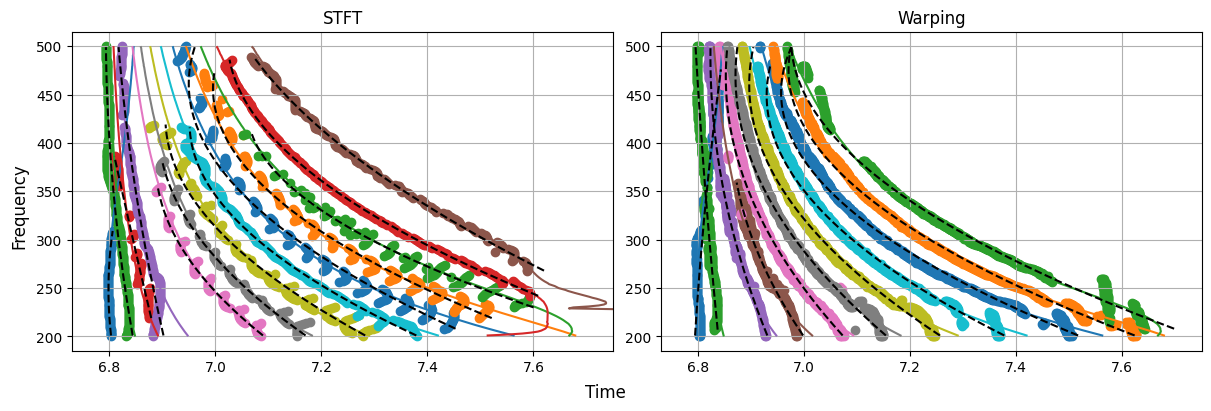

In [47]:
fig = plt.figure(layout="constrained")

for indfig, name in enumerate(data):
    ax = fig.add_subplot(1,2,indfig +1)
    for ind, p in enumerate(data[name]['peaks_coordinates']):
        mode_no = data[name]['mode_nos'][ind]
        color = f"C{mode_no}"
        ax.scatter(p[:,1], p[:,0], c=color)
        ax.plot(at_reference[mode_no], f_Vg, c=color)

    ax.set_xlim([6.73, 7.75])
    ax.plot(arrival_times[name]['jagged']['data'].T,
            arrival_times[name]['jagged']['freqs'],
            'k--')
    ax.grid()
    ax.set_title(name)
    

fig.supxlabel('Time')
fig.supylabel('Frequency')

fig.set_size_inches([12,4])

## Likelihoods

In [53]:
likelihood[name][method]['direct'].shape

(13, 29)

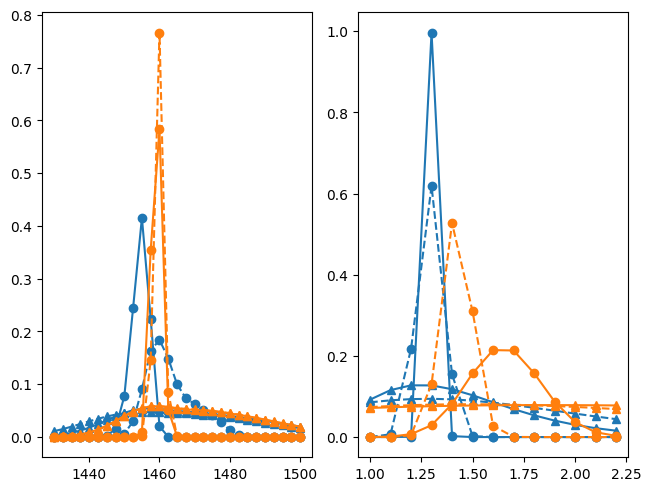

In [61]:
fig, ax = plt.subplots(1,2, layout = "constrained")
lc = {'STFT':'C0', 'Warping':'C1'}
ls = {'all':'-', 'jagged':'--'}
lss = {'direct':'^', 'combined':'o'}


for name in likelihood:
    for method in likelihood[name]:
        for ltype in likelihood[name][method]:
            Lspeed = normize(np.exp(likelihood[name][method][ltype])).sum(0)
            ax[0].plot(c, Lspeed, c=lc[name],
                       ls=ls[method], marker=lss[ltype])
            
            Ldensity = normize(np.exp(likelihood[name][method][ltype])).sum(1)
            ax[1].plot(rho, Ldensity, c=lc[name],
                       ls=ls[method], marker=lss[ltype])
        

        
        
        

### Direct Likelihood

### Joint Combined Likelihood

IndexError: index 2 is out of bounds for axis 0 with size 2

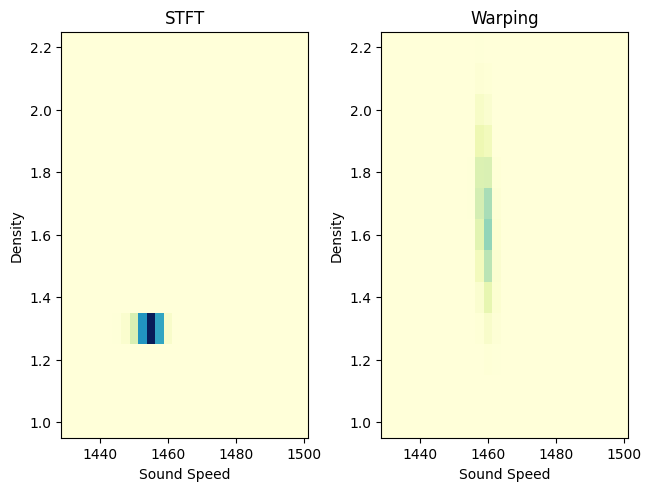

In [66]:
fig, ax = plt.subplots(1,2, layout="constrained")

vmin, vmax = (0, 0.4)
for ind, name in enumerate(likelihood):
    m1 = ax[ind].pcolormesh(c, rho,
                            normize(np.exp(likelihood[name]['combined'])),
                            vmin=vmin, vmax=vmax,
                            cmap="YlGnBu")
    ax[ind].set_xlabel("Sound Speed")
    ax[ind].set_ylabel("Density")
    ax[ind].set_title(name)
    
plt.colorbar(m1, ax=ax[2], label="Likelihood")

fig.suptitle("Joint Likelihood")

fig.set_size_inches([10,3.5])

fig.savefig("../data/output/figures/rhoc_joint_likelihood.png", dpi=600)


In [78]:

likelihood_auto = {}
for name in arrival_times:
    at_data = arrival_times[name]['jagged']['data']
    replicas = at_replica
    nmodes, nfreq = at_data.shape
    modecomb = ai.fixed_weight_gray_code(17, nmodes)

    L = ai.evaluate_likelihoods(at_data, replicas, modecomb, ai.likelihood_direct)

    best_modes = np.unravel_index(np.argmax(L), L.shape)[0]

    likelihood_auto[name] = ai.likelihood_combined(at_data, replicas[...,modecomb[best_modes],:])

    

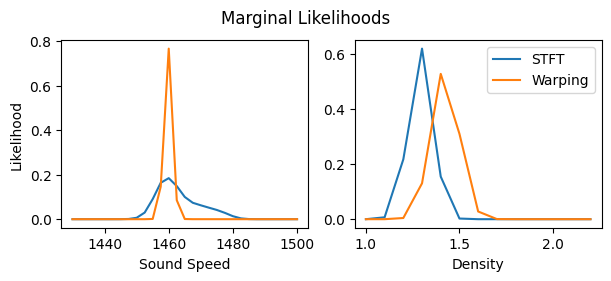

In [97]:
fig, ax = plt.subplots(1,2, layout = "constrained")
lc = {'STFT':'C0', 'Warping':'C1'}
ls = {'all':'-', 'jagged':'--'}
lss = {'direct':'^', 'combined':'o'}


for name in likelihood_auto:
    Lspeed = normize(np.exp(likelihood_auto[name])).sum(0)
    ax[0].plot(c, Lspeed, c=lc[name], label=name)
    ax[0].set_xlabel('Sound Speed')
    ax[0].set_ylabel('Likelihood')
    
    Ldensity = normize(np.exp(likelihood_auto[name])).sum(1)
    ax[1].plot(rho, Ldensity, c=lc[name], label=name)
    ax[1].set_xlabel('Density')

ax[1].legend()
fig.suptitle('Marginal Likelihoods')
fig.set_size_inches([6,2.7])

fig.savefig('../data/output/figures/marginal likelihoods.png', dpi=300)

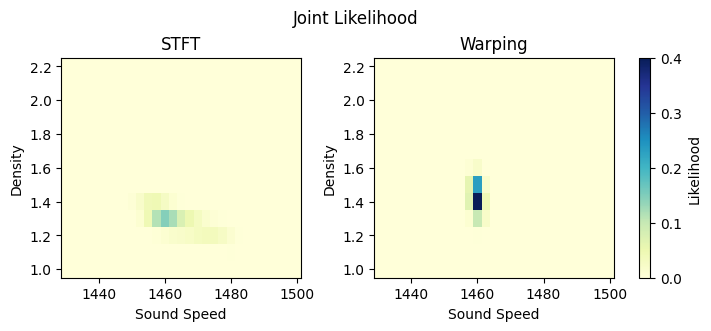

In [98]:
fig, ax = plt.subplots(1,2, layout="constrained")

vmin, vmax = (0, 0.4)
for ind, name in enumerate(likelihood):
    m1 = ax[ind].pcolormesh(c, rho,
                            normize(np.exp(likelihood_auto[name])),
                            vmin=vmin, vmax=vmax,
                            cmap="YlGnBu")
    ax[ind].set_xlabel("Sound Speed")
    ax[ind].set_ylabel("Density")
    ax[ind].set_title(name)
    
plt.colorbar(m1, ax=ax[1], label="Likelihood")

fig.suptitle("Joint Likelihood")

fig.set_size_inches([7,3.2])

fig.savefig("../data/output/figures/joint_likelihood.png", dpi=300)
